# Module 3 — Causal Concepts: Who Responds *Because* of the Offer?

This notebook explains the ideas behind the whole project in plain words, with plots
for the report. It uses two data sources:

1. **A simulated bank** where we can see what every customer would do *with* and
   *without* the offer. Real data never shows both — the simulation lets us *see* the
   concepts.
2. **The real Hillstrom data**, to show the same ideas in a real experiment.

**Sections:** 1) the question · 2) four segments · 3) the fundamental problem ·
4) randomization & ATE · 5) ATE vs CATE · 6) the probability map · 7) why response
models target the wrong people · 8) real data · 9) interview cheat sheet

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from upliftlab.config import load_config
from upliftlab.data import TARGET, TREATMENT, fetch_hillstrom_raw, select_arms
from upliftlab.eda import estimate_ate
from upliftlab.plots import AQUA, BLUE, INK_MUTED, NEUTRAL, ORANGE, SEGMENT_COLORS
from upliftlab.simulate import SEGMENTS, simulate_customers
from upliftlab.utils import set_seed

%matplotlib inline
cfg = load_config()
set_seed(cfg.project.seed)
FIGS = cfg.path("figures")

sim = simulate_customers(n=20_000, seed=cfg.project.seed)
sim.head()

,age,income_k,engagement,tenure_years,p0,p1,true_cate,y0,y1,segment,treatment,target
0,23,23.6,0.496,0.9,0.273989,0.337496,0.063506,0,0,Lost Cause,0,0
1,62,91.5,0.237,1.8,0.145761,0.187210,0.041449,0,0,Lost Cause,1,0
2,55,93.6,0.190,22.1,0.248394,0.308488,0.060094,0,0,Lost Cause,0,0
3,43,44.4,0.168,1.1,0.117105,0.151854,0.034749,1,1,Sure Thing,1,1
4,43,69.5,0.366,1.9,0.205759,0.259095,0.053335,0,0,Lost Cause,1,0


## 1. The question uplift modeling answers

A **response model** asks: *"Who will buy?"* → $P(\text{buy} \mid \text{customer})$

An **uplift model** asks: *"Who will buy **because we contacted them**?"*

$$
\text{uplift}(x) \;=\; P(\text{buy} \mid \text{offer}, x) \;-\; P(\text{buy} \mid \text{no offer}, x)
$$

The first question finds people who are likely to buy. The second finds people whose
behaviour **we can change**. Only the second one tells you where marketing money creates value.

## 2. Potential outcomes and the four customer segments

Imagine every customer has two possible futures:

- **Y(1)** — what they do **if we send** the offer
- **Y(0)** — what they do **if we don't**

Crossing the two gives four kinds of customer:

| | Doesn't buy without offer, Y(0)=0 | Buys without offer, Y(0)=1 |
|---|---|---|
| **Buys with offer, Y(1)=1** | 🟢 **Persuadable** — the offer *creates* a sale | 🔵 **Sure Thing** — buys anyway; offer cost is wasted |
| **Doesn't buy with offer, Y(1)=0** | ⚪ **Lost Cause** — won't buy either way | 🟠 **Sleeping Dog** — offer *loses* a sale (annoyed, churns) |

**Business rule:** send only to Persuadables. Never to Sleeping Dogs.

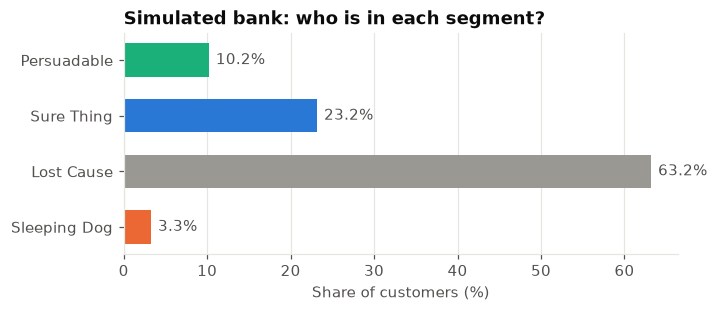

In [2]:
shares = sim["segment"].value_counts(normalize=True).reindex(SEGMENTS)

fig, ax = plt.subplots(figsize=(6.5, 2.6))
ax.barh(shares.index, shares.values * 100, color=[SEGMENT_COLORS[s] for s in shares.index], height=0.6)
for i, v in enumerate(shares.values):
    ax.text(v * 100 + 0.8, i, f"{v:.1%}", va="center", color=INK_MUTED)
ax.invert_yaxis()
ax.set_xlabel("Share of customers (%)")
ax.set_title("Simulated bank: who is in each segment?")
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "concepts_segments.png")
plt.show()

Only about **1 in 10** customers is a Persuadable. Mailing everyone means ~90% of the
budget goes to people whose decision we don't change — and a few we actively push away.

## 3. The fundamental problem of causal inference

In real life each customer either gets the offer or doesn't — so we see **only one** of
Y(0), Y(1). The other is the *counterfactual*: it never happened, so it can't be measured.

In [3]:
view = sim[["age", "engagement", "treatment", "y0", "y1", "segment"]].head(8).copy()
view["Y(1) we see"] = np.where(view["treatment"] == 1, view["y1"].astype(str), "?")
view["Y(0) we see"] = np.where(view["treatment"] == 0, view["y0"].astype(str), "?")
view[["age", "engagement", "treatment", "Y(1) we see", "Y(0) we see", "y1", "y0", "segment"]]

,age,engagement,treatment,Y(1) we see,Y(0) we see,y1,y0,segment
0,23,0.496,0,?,0,0,0,Lost Cause
1,62,0.237,1,0,?,0,0,Lost Cause
2,55,0.190,0,?,0,0,0,Lost Cause
3,43,0.168,1,1,?,1,1,Sure Thing
4,43,0.366,1,0,?,0,0,Lost Cause
5,67,0.424,1,0,?,0,0,Lost Cause
6,22,0.057,1,1,?,1,1,Sure Thing
7,58,0.595,1,0,?,0,0,Lost Cause


The left columns are what a real company sees; the right columns (`y1`, `y0`, `segment`)
exist only in a simulation.

**Consequence:** we can never label an individual as "Persuadable" from data. Instead we
estimate a **probability-level** uplift for people *like them* — the **CATE** (section 5).

## 4. Randomization rescues us: estimating the average effect

If the offer is assigned by a coin flip, the treated and control groups are the same kind
of people (we proved this for Hillstrom in Module 2). Then the control group's response
rate is a fair stand-in for "what the treated group would have done without the offer":

$$
\text{ATE} = E[Y(1) - Y(0)] \;=\; \underbrace{E[Y \mid T=1] - E[Y \mid T=0]}_{\text{observable difference in means}}
$$

In [4]:
true_ate = sim["true_cate"].mean()
est = estimate_ate(sim[TARGET], sim[TREATMENT])
print(f"True ATE (needs both futures, simulation only): {true_ate:+.2%}")
print(f"Estimated ATE (treated rate - control rate):     {est.ate:+.2%}  "
      f"95% CI [{est.ci_low:+.2%}, {est.ci_high:+.2%}]")

True ATE (needs both futures, simulation only): +6.96%
Estimated ATE (treated rate - control rate):     +6.61%  95% CI [+5.34%, +7.88%]


The estimate lands right on the truth using **only observed data** — that is the power
of a randomized experiment.

## 5. ATE vs CATE — the average hides who to target

- **ATE** (Average Treatment Effect): one number for everybody.
- **CATE** (Conditional ATE): the effect for customers with features $x$:
  $\tau(x) = E[Y(1) - Y(0) \mid X = x]$. This is what an **uplift model** estimates.
- **ITE** (Individual effect): $Y_i(1) - Y_i(0)$ — unobservable, see section 3.

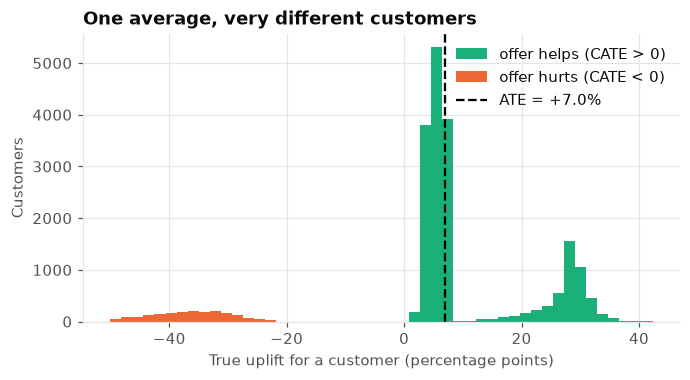

Customers the offer hurts (CATE < 0): 9.4%
Customers with CATE > 2x the ATE:     24.1%


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.4))
cate = sim["true_cate"] * 100
bins = np.linspace(cate.min(), cate.max(), 50)
ax.hist(cate[cate >= 0], bins=bins, color=AQUA, label="offer helps (CATE > 0)")
ax.hist(cate[cate < 0], bins=bins, color=ORANGE, label="offer hurts (CATE < 0)")
ax.axvline(true_ate * 100, color="black", ls="--", lw=1.5, label=f"ATE = {true_ate:+.1%}")
ax.set_xlabel("True uplift for a customer (percentage points)")
ax.set_ylabel("Customers")
ax.set_title("One average, very different customers")
ax.legend(frameon=False)
fig.savefig(FIGS / "concepts_ate_vs_cate.png")
plt.show()

print(f"Customers the offer hurts (CATE < 0): {(sim['true_cate'] < 0).mean():.1%}")
print(f"Customers with CATE > 2x the ATE:     {(sim['true_cate'] > 2 * true_ate).mean():.1%}")

The ATE says "the offer works (+7pp)". The CATE distribution says: for many people it
barely matters, for a pocket it matters a lot, and for some it **backfires**. A
campaign targeted on CATE keeps the big wins and skips the losses.

## 6. The probability map

Each dot is a customer, placed by their chance to buy **without** the offer (x-axis) and
**with** it (y-axis). The diagonal is "the offer changes nothing". Distance **above** the
diagonal is the uplift.

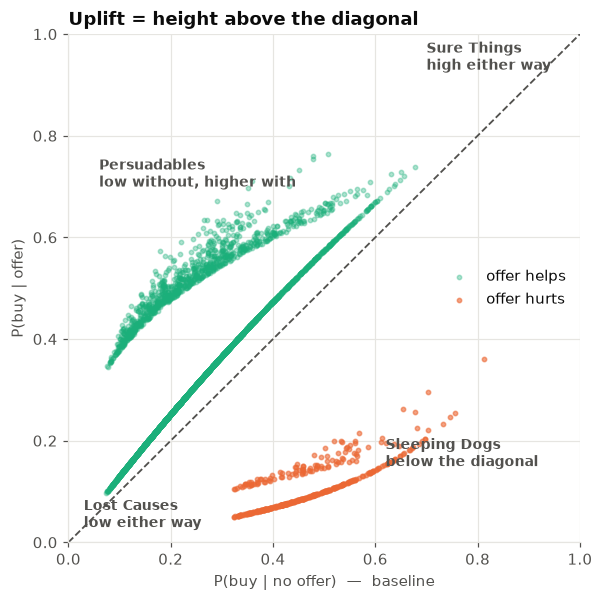

In [6]:
s = sim.sample(4000, random_state=cfg.project.seed)
helps = s["true_cate"] >= 0

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(s.loc[helps, "p0"], s.loc[helps, "p1"], s=8, alpha=0.35, color=AQUA, label="offer helps")
ax.scatter(s.loc[~helps, "p0"], s.loc[~helps, "p1"], s=8, alpha=0.6, color=ORANGE, label="offer hurts")
ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=1.2, ls="--")
notes = {
    "Persuadables\nlow without, higher with": (0.06, 0.70),
    "Sure Things\nhigh either way": (0.70, 0.93),
    "Lost Causes\nlow either way": (0.03, 0.03),
    "Sleeping Dogs\nbelow the diagonal": (0.62, 0.15),
}
for text, (x, y) in notes.items():
    ax.text(x, y, text, fontsize=9, color=INK_MUTED, fontweight="bold")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("P(buy | no offer)  —  baseline")
ax.set_ylabel("P(buy | offer)")
ax.set_title("Uplift = height above the diagonal")
ax.legend(frameon=False, loc="center right")
fig.savefig(FIGS / "concepts_probability_map.png")
plt.show()

Note the segments are **regions of likelihood**, not hard boxes: a customer with
P(buy|no offer)=0.2 and P(buy|offer)=0.5 is *probably* a Persuadable. Uplift models
rank customers by height above the diagonal.

## 7. Why "predict who buys" targets the wrong people

Give three approaches a **perfect** model of their own target and the same budget
(contact the top 20%):

- **Historical-buyer model** — trained on past purchases with no campaign, so it learns
  P(buy | no offer). The classic "propensity to buy" model.
- **Campaign response model** — a classifier trained on last campaign's data that
  ignores who got the offer. With a 50/50 split it learns the *average* of
  P(buy | offer) and P(buy | no offer).
- **Uplift model** — ranks by the uplift P(buy | offer) − P(buy | no offer).

Then look at *who* each one contacts, and how many **extra** sales that creates.

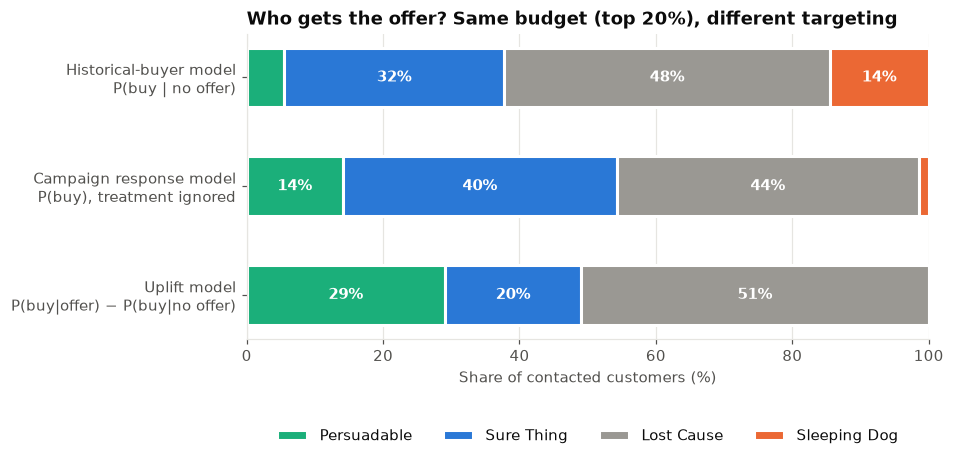

Uplift targeting creates 2.1x the extra sales of the campaign response model.


,strategy,"extra sales per 1,000 contacted",Sleeping Dogs contacted
0,Historical-buyer model P(buy | no offer),-90.5,14.5%
1,"Campaign response model P(buy), treatment ignored",136.2,1.4%
2,Uplift model P(buy|offer) − P(buy|no offer),292.4,0.0%
3,Mail everyone,69.6,3.3%


In [7]:
k = int(0.20 * len(sim))
sim["p_pooled"] = (sim["p0"] + sim["p1"]) / 2  # what a treatment-blind classifier learns
picks = {
    "Historical-buyer model\nP(buy | no offer)": sim.nlargest(k, "p0"),
    "Campaign response model\nP(buy), treatment ignored": sim.nlargest(k, "p_pooled"),
    "Uplift model\nP(buy|offer) − P(buy|no offer)": sim.nlargest(k, "true_cate"),
}

mix = pd.DataFrame({name: d["segment"].value_counts(normalize=True) for name, d in picks.items()}).T
mix = mix.reindex(columns=SEGMENTS).fillna(0)

fig, ax = plt.subplots(figsize=(8, 3.6))
left = np.zeros(len(mix))
for seg in SEGMENTS:
    vals = mix[seg].values * 100
    ax.barh(mix.index, vals, left=left, color=SEGMENT_COLORS[seg], label=seg,
            height=0.55, edgecolor="white", linewidth=2)
    for i, (l, v) in enumerate(zip(left, vals)):
        if v >= 6:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of contacted customers (%)")
ax.set_title("Who gets the offer? Same budget (top 20%), different targeting")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.25))
ax.grid(axis="y", visible=False)
fig.savefig(FIGS / "concepts_response_vs_uplift.png")
plt.show()

rows = []
for name, d in picks.items():
    rows.append({"strategy": name.replace("\n", " "),
                 "extra sales per 1,000 contacted": round(d["true_cate"].mean() * 1000, 1),
                 "Sleeping Dogs contacted": f"{(d['segment'] == 'Sleeping Dog').mean():.1%}"})
rows.append({"strategy": "Mail everyone",
             "extra sales per 1,000 contacted": round(true_ate * 1000, 1),
             "Sleeping Dogs contacted": f"{(sim['segment'] == 'Sleeping Dog').mean():.1%}"})
results = pd.DataFrame(rows)
ratio = results.iloc[2, 1] / results.iloc[1, 1]
print(f"Uplift targeting creates {ratio:.1f}x the extra sales of the campaign response model.")
results

**The key insight of the project.**

- The **historical-buyer model** is the worst: engaged, loyal customers *look* like the
  best prospects, but that is exactly where the Sleeping Dogs live. It contacts the most
  of them and ends up with **fewer** sales than doing nothing.
- The **campaign response model** fills its budget with **Sure Things** — people who buy
  anyway.
- The **uplift model** contacts the most **Persuadables** and roughly doubles the
  incremental sales of the response model with the same budget.

Notice that even the uplift model's picks are about half "Lost Causes": a customer with
+30pp uplift still has a good chance of not responding. Uplift is about **shifting
probabilities across a group**, not guaranteeing individual outcomes.

A response model can have a great AUC and still be the wrong tool: it answers a question
the business didn't ask.

## 8. Back to real data: Hillstrom CATE by subgroup

We can't see segments in real data, but we *can* estimate CATE for groups of similar
customers (treated rate − control rate inside each group). Here: the women's email,
split by whether customers bought women's products last year and whether they are new.

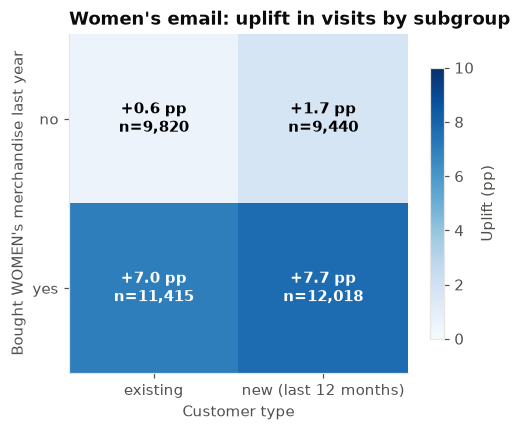

In [8]:
hill = select_arms(fetch_hillstrom_raw(cfg), cfg.data.hillstrom.treatment_mode)

grid = np.zeros((2, 2)); counts = np.zeros((2, 2), dtype=int)
for w in (0, 1):
    for m in (0, 1):  # m = newbie
        part = hill[(hill["womens"] == w) & (hill["newbie"] == m)]
        grid[w, m] = estimate_ate(part[TARGET], part[TREATMENT]).ate * 100
        counts[w, m] = len(part)

fig, ax = plt.subplots(figsize=(5.2, 4))
im = ax.imshow(grid, cmap="Blues", vmin=0, vmax=max(10, grid.max()))
for w in (0, 1):
    for m in (0, 1):
        color = "white" if grid[w, m] > 6 else "black"
        ax.text(m, w, f"{grid[w, m]:+.1f} pp\nn={counts[w, m]:,}", ha="center", va="center",
                color=color, fontweight="bold")
ax.set_xticks([0, 1], ["existing", "new (last 12 months)"]); ax.set_yticks([0, 1], ["no", "yes"])
ax.set_xlabel("Customer type")
ax.set_ylabel("Bought WOMEN's merchandise last year")
ax.set_title("Women's email: uplift in visits by subgroup")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Uplift (pp)", shrink=0.8)
fig.savefig(FIGS / "concepts_hillstrom_cate_heatmap.png")
plt.show()

Same email, very different effects: customers who previously bought women's products
respond several times more strongly than those who didn't, and new customers respond a
bit more than existing ones. (Every Hillstrom customer bought men's *or* women's items,
so "didn't buy women's" means "men's-only buyer".) A two-feature split already shows
heterogeneity; the uplift models in Modules 5–6 learn it
from **all features at once**, giving each customer their own CATE estimate.

## 9. Interview cheat sheet

| Term | One-line answer |
|---|---|
| **Uplift** | The change in a customer's probability of responding *caused by* the treatment: P(Y=1\|T=1,x) − P(Y=1\|T=0,x). |
| **Potential outcomes** | Y(1) and Y(0): what a customer would do with and without treatment (Rubin causal model). |
| **Fundamental problem** | We observe only one potential outcome per person, so individual effects are never directly measurable. |
| **ATE** | Average effect over everyone, E[Y(1)−Y(0)]; with randomization = difference in group means. |
| **CATE** | Average effect for customers with features x, τ(x). Uplift models estimate this. |
| **ITE** | Y_i(1)−Y_i(0) for one person; unobservable. CATE is our best estimate of it. |
| **Persuadable / Sure Thing / Lost Cause / Sleeping Dog** | (Y0,Y1) = (0,1) / (1,1) / (0,0) / (1,0). Target only Persuadables. |
| **Why randomization matters** | It makes treated and control comparable (no confounding), so differences are causal. |

**Assumptions to name if asked:**
1. **Unconfoundedness** — treatment is independent of potential outcomes given X (guaranteed by randomization).
2. **Overlap / positivity** — every type of customer has a chance of being in both groups (0 < P(T=1|x) < 1).
3. **SUTVA** — one customer's treatment doesn't affect another's outcome, and there's one version of the treatment.

**30-second answer to "why not a normal classifier?"**
> A classifier predicts who buys, so it ranks Sure Things at the top — customers who'd
> buy anyway. That wastes budget and can even trigger Sleeping Dogs. Uplift modeling
> estimates the *difference* the offer makes per customer, so the budget goes to people
> whose behaviour actually changes. In my simulation, with the same budget, the uplift
> ranking created about twice the incremental sales of a response model, and a
> classic "propensity to buy" model actually lost sales by contacting Sleeping Dogs.